# Citi Bike Avalibility Predictor

Performing EDA and model training and testing

### Import Libraries

In [39]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone, timedelta
import holidays
import seaborn as sns
import json
import meteostat as ms

### Import station data
Map each station's 'shortname' to their important features

In [2]:
stations_df = pd.read_csv('citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [45]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


## Data Processing

### Final Pipeline

Implemented Basic Time and Location Features

In [50]:
df_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','timestamp','minute',
                   ]

# 'temp','prcp','snwd','wspd'

def add_features(df):
    
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['minute'] = df['timestamp'].dt.minute
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)


    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)
    # df = add_weather(df)

    return df

def process_file(csv_file):
    df = pd.read_csv(csv_file)
    df['timestamp'] = pd.to_datetime(df['station_status_last_reported'], format="%Y-%m-%d %H:%M:%S%z", utc=True)
    df = add_features(df)


    print(f"Before dropping NA: {df.shape[0]} rows")
    df = df[df_columns + ['percentage_available']].dropna()
    print(f"After dropping NA: {df.shape[0]} rows")
    df['shortname'] = df['shortname'].astype('category')

    

    return df
    

### Some Feature Experimentation

- **Tested a station volitatity feature**: The idea was for the trees to spend less splits finding stations that had predicting patterns. 
  The model ended up performing worse though (mostly due to poor implemention of the features), but just running more iterations
  to construct a deeper tree is sufficient

- **Potential Weather feature**: I considered adding a weather feature, relying on weather forecast (will implement later)

- **Potential Lag Features**: Maybe later as well but not sure how significant this will be


In [ ]:
def add_vol(df):

    hourly_variances = df.groupby(['station_id', 'Hour'])['percentage_available'].var()
    station_volatility = hourly_variances.groupby(level=0).mean()
    df['Volatility'] = df['station_id'].map(station_volatility)
    return df;

In [44]:

def add_weather(df):
    df['hour_key'] = df['timestamp'].dt.floor('H')
    manhattan = ms.Point(40.78, -73.96)

    start = dt(2017, 1, 1)
    end = dt(2020, 1, 1) 

    stations = ms.stations.nearby(manhattan, limit=4)


    print("Fetching data... this may take a moment.")
    data = ms.hourly(stations, start, end)
    df_weather = data.fetch()

    df_weather = df_weather.reset_index()
    df_weather['time'] = (
        df_weather['time']
            .dt.tz_localize('UTC')         
            .dt.tz_convert('America/New_York') 
    )
    df_weather = df_weather[['time', 'temp','prcp','snwd','wspd']]
    df_weather = df_weather.fillna(0)
    

    df_final = pd.merge(
    df, 
    df_weather, 
    left_on='hour_key', 
    right_on='time', 
    how='left'       
    )

    return df_final

## Baseline XgBoost

In [4]:
# Import necessary libraries for time series modeling
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor


In [56]:
df = process_file('mediumset_14thstbelow.csv')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','minute',
                   ]


X_train = df[feature_columns]
y_train = df['percentage_available']

Before dropping NA: 1445829 rows
After dropping NA: 1444660 rows


In [54]:
val_dataset = process_file('smallvalset_14thstbelow.csv')
X_val = val_dataset[feature_columns]
y_val = val_dataset['percentage_available']

Before dropping NA: 13430 rows
After dropping NA: 13417 rows


In [28]:
def evaluate_model(predicted, actual):
    train_mae = mean_absolute_error(predicted, actual)
    train_rmse = np.sqrt(mean_squared_error(predicted, actual))
    train_r2 = r2_score(predicted, actual)

    print(f"  MAE:  {train_mae:.4f}")
    print(f"  RMSE: {train_rmse:.4f}")
    print(f"  R²:   {train_r2:.4f}")

### Base Line Model Training

In [57]:
# Train baseline XGBoost model
print("Training baseline XGBoost model...")

# Initialize XGBoost regressor with default parameters
baseline_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.1,
    depth=6,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    verbose=100
)

baseline_model.fit(X_train, y_train, cat_features=['shortname', 'Month','Day'], eval_set=(X_val, y_val))

y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)


print("\n=== Baseline Model Performance ===")
print(f"\nTraining Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R²:   {train_r2:.4f}")

print(f"\nValidation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")



Training baseline XGBoost model...
0:	learn: 0.3276813	test: 0.3221453	best: 0.3221453 (0)	total: 531ms	remaining: 13m 15s
100:	learn: 0.2415272	test: 0.2413786	best: 0.2413786 (100)	total: 36.4s	remaining: 8m 24s
200:	learn: 0.2355511	test: 0.2352145	best: 0.2352145 (200)	total: 1m 15s	remaining: 8m 7s


KeyboardInterrupt: 

In [44]:
val_dataset = process_file('valset_dense_fewstations.csv')
X_smallval = val_dataset[feature_columns]
y_smallval = val_dataset['percentage_available']

y_smallval_pred = baseline_model.predict(X_smallval)


val_mae = mean_absolute_error(y_smallval, y_smallval_pred)
val_rmse = np.sqrt(mean_squared_error(y_smallval, y_smallval_pred))
val_r2 = r2_score(y_smallval, y_smallval_pred)

print(f"\nSmall Validation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")

Before dropping NA: 2608503 rows
After dropping NA: 2606512 rows

Small Validation Set:
  MAE:  0.1884
  RMSE: 0.2376
  R²:   0.4860


In [16]:
with open('true_valid_stations_list.json', 'w') as f:
    json.dump(list(X_val['shortname'].unique()), f)



In [9]:
baseline_model.save_model("Working_model.cbm")

### Baseline model graph

In [39]:
df['shortname'].unique()


['5288.08', '5532.01', '4846.01', '5279.03', '6030.04', ..., '5382.06', '5391.06', '5515.02', '5436.09', '5575.08']
Length: 84
Categories (84, object): ['4846.01', '4889.06', '4953.04', '4962.01', ..., '5947.04', '5964.01', '6030.04', '6039.06']

Canal St & Rutgers St :


<Axes: xlabel='timestamp', ylabel='predictions'>

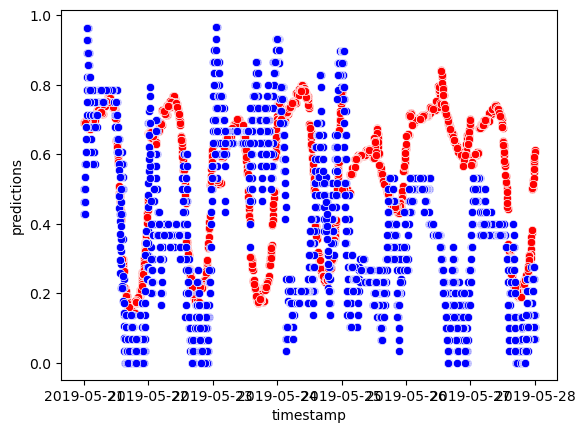

In [56]:

val_dataset['predictions'] = y_smallval_pred

SHORTNAME = '5303.08'

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,5,21, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,5,28, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')

sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
# sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5532.01') & timeframe_graphed], x='timestamp', y='predictions', color = 'blue')


### Model Perforamnce logs

In [10]:

model_logs = pd.read_csv('model_logs.csv')
model_logs.loc[len(model_logs)] = pd.Series({
    'model_name': 'upgraded to 1,500 iterations',
    'train_mae': val_mae,
    'train_rmse': val_rmse,
    'R^2': val_r2,
    'hyperparams': 'default',
    'features_used': 'Standard',
    'notes': 'still underfit but gains were minial, 10  minutes to train'
})

model_logs.to_csv('model_logs.csv', index=False)

In [29]:
model_logs = pd.read_csv('model_logs.csv')
pd.set_option('display.max_colwidth', None)
model_logs

,model_name,train_mae,train_rmse,R^2,hyperparams,features_used,notes
0,Baseline CatBoost,0.143460,0.187209,0.624322,default,"NO lag features, baseline","Default parameters, seems kinda weak, ran on medium sized dataset with just sparse data from the first 2 csvs"
1,Cat Boost with first before time stamp lag,0.019427,0.044316,0.978949,default,Only lag from previous measurement and time since last measurement,"Pretty good but I feel like the predictive power is limited since the lags are so close, will have to figure out better lag design"
2,Standard with more data and from 2017 and 2018,0.163594,0.210014,0.515280,"default, will change to 500 iteration since conversion seems to be at around 200",Standard,uhhh i feel like more data had a very marginal improvement
3,Standard with more data and from 2017 and 2018,0.215938,0.277457,0.243575,default,Standard,oops will start logging test results from now on
4,"Standard using only stations in Manhatten under 14th st. Used 2017 to 2018 data with 100,000 cols per csv, used 10,000 per csv for cross val",0.202173,0.256919,0.419616,default,"Standard, added volitatity",lowkey using used stations make big difference
5,"same as previous but I took out volitatiy, turned out to be bad i guess",0.200971,0.255792,0.424698,default,Standard,lowkey using used stations make big difference
6,added minute feature,0.201037,0.255623,0.425459,default,Standard + minute,literally no difference i guess will keep in the model
7,changed max iterations to 1000,0.197427,0.253156,0.436494,default,Standard,"lowkey max iterations makes a gud difference, model is still underfitting and could be better with more"
8,"used dataset with 500,000 rows by per csv",0.173122,0.217899,0.582525,default,Standard,holy shit more data actually matters so much


### Quick Baseline Comparison Test

This below model just predicts the 2019 based on the capacities of the same date in 2018.
I tested this model out of curiosity to see how effective my XG Boost, it serves as another baseline to compare to.

The simple "last year" model performed terribly, much worse than I would have thought

In [36]:
df_2018 = df[(df['timestamp'] >= dt(2018,1,1, tzinfo = timezone.utc)) & (df['timestamp'] < dt(2018,12,31, tzinfo = timezone.utc))]
df_2018 = df_2018.sort_values('timestamp')
df_2019 = val_dataset
df_2019 = df_2019.sort_values('timestamp')
df_2019['last_year_time'] = df_2019['timestamp'] - timedelta(days = 365)

df_lag = pd.merge_asof(
    df_2019,
    df_2018[["shortname","timestamp", "percentage_available"]],
    left_on="last_year_time",
    right_on="timestamp",
    direction="backward",
    by = 'shortname',
    suffixes=("", "_lag_1h")
)

df_lag = df_lag.dropna(subset=["percentage_available_lag_1h"])





In [38]:
print("Evaluating simple year back model:")
evaluate_model(df_lag['percentage_available'], df_lag['percentage_available_lag_1h'])

Evaluating simple year back model:
  MAE:  0.3467
  RMSE: 0.4380
  R²:   -0.7736


In [37]:
df_lag


,shortname,Month,Day,Hour,IsWeekend,IsHoliday,IsNonWorkingDay,lat,lon,IsRushHour,timestamp,minute,percentage_available,last_year_time,timestamp_lag_1h,percentage_available_lag_1h
24,5391.06,1,1,5,0,0,0,40.719392,-74.002472,0,2019-01-01 05:12:21+00:00,12,0.810811,2018-01-01 05:12:21+00:00,2018-01-01 05:06:50+00:00,0.179487
50,5391.06,1,1,5,0,0,0,40.719392,-74.002472,0,2019-01-01 05:36:12+00:00,36,0.810811,2018-01-01 05:36:12+00:00,2018-01-01 05:06:50+00:00,0.179487
83,6039.06,1,1,9,0,0,0,40.739323,-74.008119,1,2019-01-01 09:01:58+00:00,1,0.975000,2018-01-01 09:01:58+00:00,2018-01-01 08:08:54+00:00,0.200000
84,5532.01,1,1,9,0,0,0,40.723627,-73.999496,1,2019-01-01 09:23:08+00:00,23,0.931034,2018-01-01 09:23:08+00:00,2018-01-01 08:49:57+00:00,0.032258
85,5545.04,1,1,9,0,0,0,40.722992,-73.979955,1,2019-01-01 09:27:49+00:00,27,0.500000,2018-01-01 09:27:49+00:00,2018-01-01 07:53:46+00:00,0.161290
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133906,5922.08,12,0,16,0,0,0,40.736529,-74.006180,1,2019-12-30 16:39:02+00:00,39,0.592593,2018-12-30 16:39:02+00:00,2018-12-30 10:55:52+00:00,1.000000
133907,5687.04,12,0,16,0,0,0,40.727103,-74.002971,1,2019-12-30 16:42:01+00:00,42,0.535714,2018-12-30 16:42:01+00:00,2018-12-30 10:44:29+00:00,0.896552
133908,5391.06,12,0,16,0,0,0,40.719392,-74.002472,1,2019-12-30 16:46:53+00:00,46,0.297297,2018-12-30 16:46:53+00:00,2018-12-30 10:53:02+00:00,0.552632
133909,5453.01,12,0,16,0,0,0,40.721101,-73.991925,1,2019-12-30 16:51:47+00:00,51,0.675676,2018-12-30 16:51:47+00:00,2018-12-30 10:55:11+00:00,0.833333
